# Module 5 - Design Principles: Space, Motion, Value and Color

**Name:** Clement Scaccia  
**Course:** Data Visualization  
**Tool:** Python (pandas, matplotlib)

Two visualizations, each built around one focal point:

| # | Visualization | Focal point | Principles used |
|---|---|---|---|
| 1 | US annual inflation, 1960-2025 | the 1970s-80s inflation era was much worse and longer than 2021-22 | **space, value, color** |
| 2 | PBA men's soccer 2026, points over the season | the 3-game losing streak in October, and the bounce back after it | **illusion of motion, color, space** |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colormaps
from matplotlib.collections import LineCollection

cpi = pd.read_csv("../Module4/cleaned_data/us_cpi_monthly_bls_cleaned.csv", parse_dates=["Date"])
games = pd.read_csv("../data/personal/pba_mens_soccer_2026_results.csv", parse_dates=["Date"])

INK = "#0b0b0b"; INK2 = "#52514e"; GRAY = "#d4d3cd"; BG = "#fcfcfb"
plt.rcParams.update({"figure.facecolor": BG, "axes.facecolor": BG, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "xtick.color": INK2, "ytick.color": INK2})

---
## Visualization 1: US annual inflation, 1960-2025

**Focus:** two high-inflation periods stand out, but the 1970s-80s were much worse than 2021-22. Inflation went over 5% in 12 years between 1969 and 1982 (peaking at 13.5% in 1980), compared to just 1 year (8.0% in 2022) in the recent spike.

Annual inflation = % change in the yearly average CPI (2026 is left out because the year isn't finished).

In [2]:
annual = cpi.groupby(cpi["Date"].dt.year)["Index"].mean().pct_change() * 100
annual = annual.loc[1960:2025]
HIGH = 5
hot = annual > HIGH
print("Years above 5%:", list(annual[hot].index))

Years above 5%: [1969, 1970, 1973, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982, 1990, 2022]


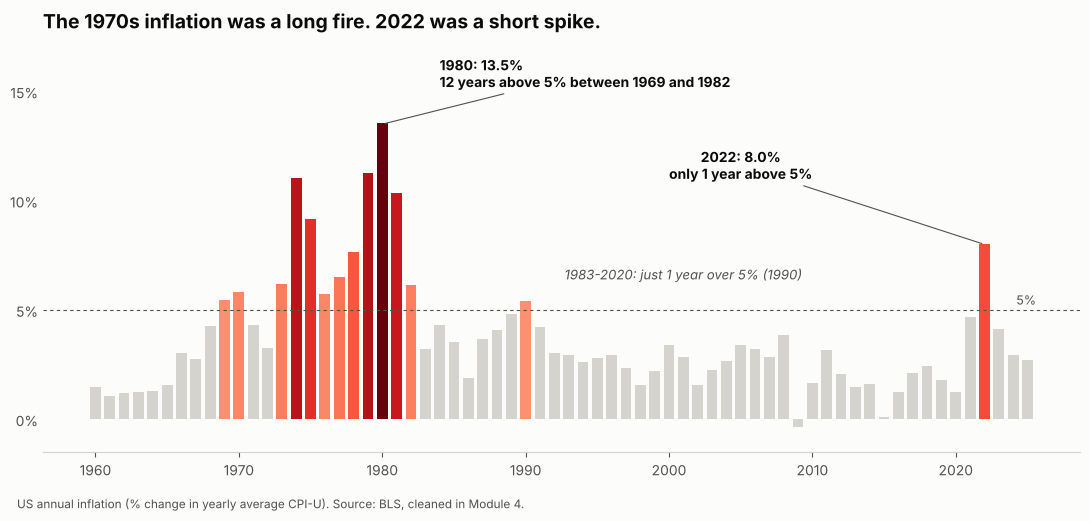

In [3]:
fig, ax = plt.subplots(figsize=(11, 5.2))

# VALUE: only years above 5% get color, and darker = higher inflation (one hue, light to dark)
cmap = colormaps["Reds"]
norm = plt.Normalize(HIGH, annual.max())
colors = [cmap(0.35 + 0.65 * norm(v)) if v > HIGH else GRAY for v in annual]
ax.bar(annual.index, annual.values, color=colors, width=0.75)

# COLOR: everything normal is the same quiet gray, so red only shows up where it matters
ax.axhline(HIGH, color=INK2, linewidth=0.8, linestyle=(0, (3, 3)))
ax.text(2025.6, HIGH + 0.25, "5%", color=INK2, fontsize=9, ha="right")

# SPACE: no gridlines, no box, few ticks; labels sit in the empty space above the bars
ax.set_yticks([0, 5, 10, 15]); ax.set_yticklabels(["0%", "5%", "10%", "15%"])
ax.set_ylim(-1.5, 17)
ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)
ax.spines["bottom"].set_color(GRAY)
ax.set_xticks(range(1960, 2030, 10))

ax.annotate("1980: 13.5%\n12 years above 5% between 1969 and 1982",
            xy=(1980, 13.5), xytext=(1984, 15.2), fontsize=10, color=INK, fontweight="bold",
            arrowprops=dict(arrowstyle="-", color=INK2, linewidth=0.8))
ax.annotate("2022: 8.0%\nonly 1 year above 5%", xy=(2022, 8.0), xytext=(2005, 11),
            fontsize=10, color=INK, fontweight="bold", ha="center",
            arrowprops=dict(arrowstyle="-", color=INK2, linewidth=0.8))
ax.text(2001, 6.4, "1983-2020: just 1 year over 5% (1990)", fontsize=9.5, color=INK2, ha="center", style="italic")

ax.set_title("The 1970s inflation was a long fire. 2022 was a short spike.",
             loc="left", fontsize=14, fontweight="bold", color=INK, pad=14)
plt.tight_layout(rect=(0, 0.04, 1, 1))
fig.text(0.02, 0.012, "US annual inflation (% change in yearly average CPI-U). Source: BLS, cleaned in Module 4.",
         fontsize=8.5, color=INK2)
plt.savefig("images/viz1_inflation_space_value_color.png", dpi=150)
plt.show()

**How the principles create the focus:**
- **Color:** all normal years (5% or less) are the same light gray, and only the high-inflation years are red. Because there's just one accent color, the eye goes straight to the two red clusters and ignores the rest.
- **Value:** inside the red, darker = higher inflation (one hue going from light to dark). So 1974, 1979-81 are the darkest bars, and 2022 is a medium red, which shows that it was less severe without needing to read the axis.
- **Space:** I removed the gridlines, the box and most ticks so there's a lot of empty space, then used that space for the two labels right next to the bars they describe. The long gray stretch in the middle is left mostly empty on purpose, so the calm period between the two eras (only 1990 went over 5%) is something you can see.

---
## Visualization 2: PBA men's soccer 2026, points over the season

**Focus:** after a good run (4 wins in 6 games from Sep 16 to Oct 7) we stalled with **3 losses in a row** in October (Florida Southern, Florida Tech, Lynn), then bounced back with a win against Eckerd.

Points use standard soccer scoring: win = 3, tie = 1, loss = 0, added up game by game.

In [4]:
games["Points"] = games["Result"].map({"W": 3, "T": 1, "L": 0})
games["Total"] = games["Points"].cumsum()
games["Game"] = range(1, len(games) + 1)
games[["Game", "Date", "Opponent", "Result", "PBA_Goals", "Opp_Goals", "Total"]]

,Game,Date,Opponent,Result,PBA_Goals,Opp_Goals,Total
0,1,2026-08-27,Lincoln Memorial,W,2,0,3
1,2,2026-08-29,Carson-Newman,T,2,2,4
2,3,2026-09-02,Young Harris,T,1,1,5
3,4,2026-09-04,North Georgia,L,0,2,5
4,5,2026-09-12,Emory & Henry,T,0,0,6
5,6,2026-09-16,Barry,W,1,0,9
6,7,2026-09-19,Rollins,L,0,1,9
7,8,2026-09-23,Fla. Memorial,W,8,0,12
8,9,2026-09-26,Saint Leo,W,1,0,15
9,10,2026-09-30,Nova Southeastern,T,2,2,16


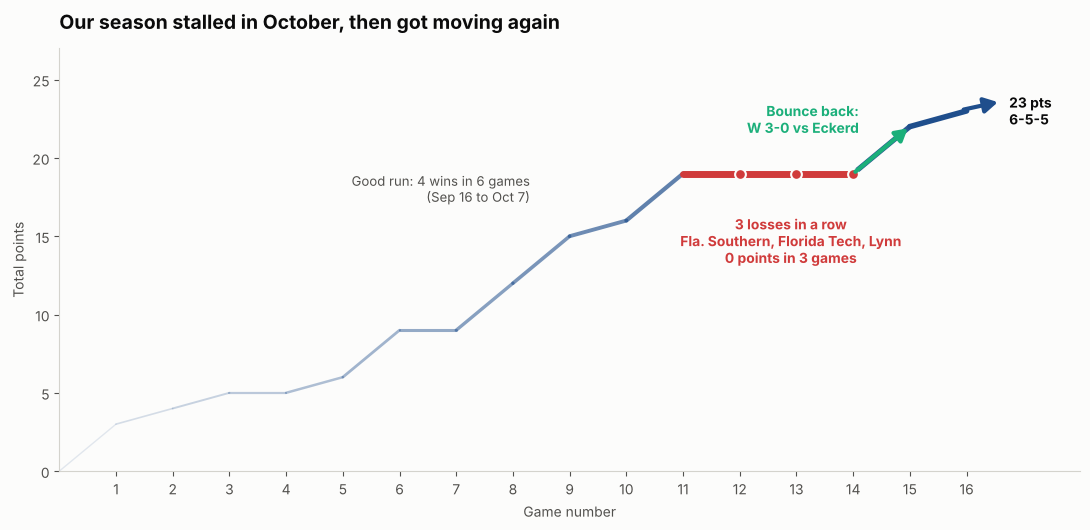

In [5]:
x = np.concatenate([[0], games["Game"].values])
y = np.concatenate([[0], games["Total"].values])
streak = games.index[(games["Date"] >= "2026-10-10") & (games["Date"] <= "2026-10-21")]
s0, s1 = streak.min() + 1, streak.max() + 1          # game numbers 12 to 14

fig, ax = plt.subplots(figsize=(11, 5.4))

# MOTION: the path is drawn as a "comet trail", older games thin and faded, recent games thick and solid
pts = np.array([x, y]).T.reshape(-1, 1, 2)
segs = np.concatenate([pts[:-1], pts[1:]], axis=1)
fade = np.linspace(0.12, 1, len(segs))
seg_colors = [(31/255, 78/255, 140/255, a) for a in fade]
widths = np.linspace(1, 4, len(segs))
ax.add_collection(LineCollection(segs, colors=seg_colors, linewidths=widths, capstyle="round"))

# COLOR: the losing streak is the only red part of the chart
ax.plot([s0 - 1, s1], [y[s0 - 1], y[s1]], color="#d03b3b", linewidth=5, solid_capstyle="round", zorder=4)
for g in range(s0, s1 + 1):
    ax.scatter(g, y[g], s=60, color="#d03b3b", edgecolor=BG, linewidth=1.5, zorder=5)

# MOTION: arrow on the bounce back and at the end, so the line "moves" forward
ax.annotate("", xy=(16.6, 23.6), xytext=(15.9, 23.05),
            arrowprops=dict(arrowstyle="-|>,head_length=0.8,head_width=0.45", color="#1f4e8c", linewidth=3))
ax.annotate("", xy=(15, 22), xytext=(14, 19),
            arrowprops=dict(arrowstyle="-|>,head_length=0.7,head_width=0.4", color="#1baf7a", linewidth=3), zorder=6)

# SPACE: no grid, labels placed in open space, only the key games are named
ax.text(12.9, 16.3, "3 losses in a row\nFla. Southern, Florida Tech, Lynn\n0 points in 3 games",
        color="#d03b3b", fontsize=10, fontweight="bold", ha="center", va="top")
ax.text(14.1, 21.6, "Bounce back:\nW 3-0 vs Eckerd", color="#1baf7a", fontsize=10, fontweight="bold", ha="right")
ax.text(8.3, 17.2, "Good run: 4 wins in 6 games\n(Sep 16 to Oct 7)", color=INK2, fontsize=9.5, ha="right")
ax.text(16.75, 23, f"{y[-1]} pts\n6-5-5", color=INK, fontsize=10, fontweight="bold", va="center")

ax.set_xlim(0, 18); ax.set_ylim(0, 27)
ax.set_xticks(range(1, 17)); ax.set_xlabel("Game number", color=INK2)
ax.set_ylabel("Total points", color=INK2)
ax.spines["left"].set_color(GRAY); ax.spines["bottom"].set_color(GRAY)
ax.set_title("Our season stalled in October, then got moving again",
             loc="left", fontsize=14, fontweight="bold", color=INK, pad=14)
plt.tight_layout()
plt.savefig("images/viz2_season_motion_color.png", dpi=150)
plt.show()

**How the principles create the focus:**
- **Illusion of motion:** the line is drawn like a comet trail. Early games are thin and faded, recent games are thick and solid, so the line looks like it's moving from left to right. The arrows on the bounce back and at the end of the season push the eye forward, like the season is still going.
- **Color:** the losing streak is the only red part of the chart, so it's the first thing you see, even though it's a flat line, which normally wouldn't stand out. The bounce back is green, and the rest stays blue.
- **Space:** no gridlines, and only 3 parts of the season get a label, each placed in open space next to the section it describes, instead of labeling all 16 games.

---
## Summary

| | Visualization 1: Inflation | Visualization 2: Soccer season |
|---|---|---|
| **Focus** | 1970s-80s inflation was much longer and worse than 2022 | the October losing streak and bounce back |
| **Space** | no grid or box, labels in empty space, the calm middle years left empty | no grid, only 3 labeled moments |
| **Motion** | not used, the data is a comparison, not a journey | comet trail line + arrows |
| **Value** | darker red = higher inflation | line gets darker and thicker over time |
| **Color** | gray for normal, red only for high | red only for the losing streak, green for the bounce back |